# adaptive_cut tutorial

A single horizontal cut of a dendrogram takes every cluster at the same level. The
**adaptive cut** takes each branch at its own level and keeps the multi-level cut that
maximises an objective summed over clusters. This notebook shows it on

1. networks (link communities scored by partition density),
2. point clouds (Ward linkage, clusters scored by a Gaussian BIC),
3. classic datasets (iris, wine, digits).

Install with `pip install "adaptive_cut[all]" matplotlib scikit-learn`. Run the notebook
from the `examples/` folder: it imports the helpers in `sbm.py`, `points.py` and `plots.py`.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import points
import sbm
from plots import blobs_figure, digits_figure, link_matrix_figure

import adaptive_cut as ac

## 1. Networks: varying density versus balanced

Two stochastic block models with five blocks. In the first, block densities run from 1
down to 0.1 and the sparser blocks are larger. In the second, all blocks are alike.
`link_communities` builds the edge dendrogram (Jaccard similarity, single linkage), finds the
best single-level cut and runs the adaptive cut.

In [2]:
nets = sbm.networks(seed=0)
res = {name: ac.link_communities(edges, n_steps=50_000, rng=0) for name, edges in nets.items()}
for name, r in res.items():
    print(
        f"{name:>16}: B={r.balancedness:.2f}  D single-level={r.level_cut.value:.3f} "
        f"({r.level_cut.n_clusters})  D adaptive={r.partition_density:.3f} ({r.cut.n_clusters})"
    )

 varying density: B=0.26  D single-level=0.422 (386)  D adaptive=0.466 (152)
        balanced: B=0.66  D single-level=0.618 (16)  D adaptive=0.619 (14)


Each edge of the adjacency matrix is coloured by its link community (communities of one or
two edges are grey). In the varying-density network the single-level cut that suits the dense
blocks leaves the fourth block in fragments; the adaptive cut groups it.

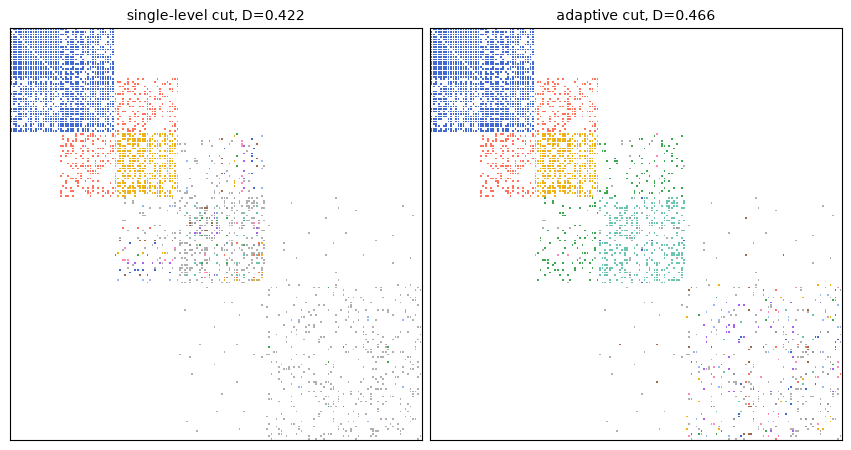

In [3]:
vd = res["varying density"]
link_matrix_figure(
    vd,
    [vd.level_cut, vd.cut],
    [
        f"single-level cut, D={vd.level_cut.value:.3f}",
        f"adaptive cut, D={vd.partition_density:.3f}",
    ],
);

### Balancedness level by level

`balancedness(Z, return_levels=True)` returns, for every level of the dendrogram, how even
its split is between the most skewed (0) and the most even (1) split into the same number of
clusters. `B` is the mean over levels.

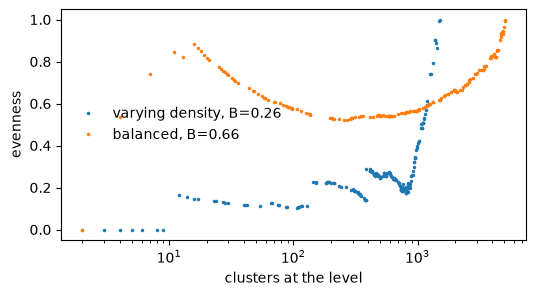

In [4]:
fig, ax = plt.subplots(figsize=(6, 3))
for name, r in res.items():
    B, lv = ac.balancedness(r.Z, return_levels=True)
    ax.plot(lv.n_clusters, lv.ratio, ".", ms=3, label=f"{name}, B={B:.2f}")
ax.set_xscale("log")
ax.set_xlabel("clusters at the level")
ax.set_ylabel("evenness")
ax.legend(frameon=False);

Each network gets one result object: `r.cut.labels` is the community of every edge
(`r.edges[i]`), `r.communities()` lists the (overlapping) node sets and `r.memberships()` is a
sparse node-by-community matrix.

In [5]:
comms = vd.communities()
print(len(comms), "communities; largest has", max(len(c) for c in comms), "nodes")
print(vd.memberships().shape)

152 communities; largest has 51 nodes
(166, 152)


## 2. Point clouds: clusters at different scales

Any scipy linkage matrix works. The objective must be a sum over clusters: here each cluster
scores the BIC of one diagonal Gaussian fitted to it (`points.gaussian_scores`, computed
bottom-up in O(n d)). The data have three tight blobs next to two wide ones.

B = 0.92
single-level cut: 3 clusters, ARI = 0.69
adaptive cut:     5 clusters, ARI = 0.96


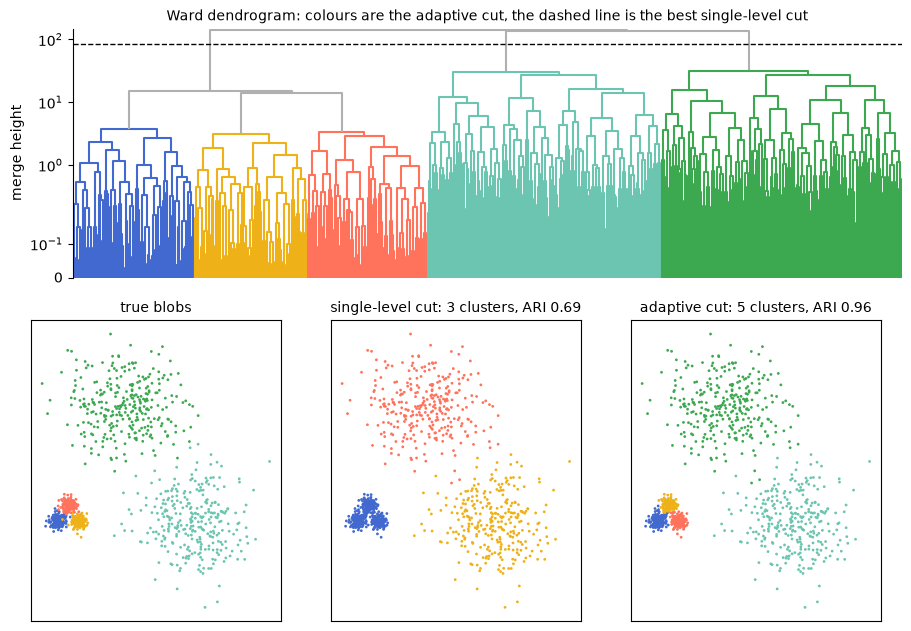

In [6]:
out = points.run(seed=0)
blobs_figure(out, points.ari);

The best single-level cut has to choose: a height that separates the three tight blobs also
cuts the wide blobs into pieces. The adaptive cut takes the tight blobs low in the tree and the
wide blobs high.

### Exact optimum versus the sampler

Because the objective is additive over a tree, `optimal_cut` finds its exact maximum in one
O(n) pass. `adaptive_cut` searches the same space with the paper's Metropolis-Hastings chain.
Here the chain does not leave the single-level cut: splitting the tight blobs first goes
through a cut that scores lower, which the chain accepts with probability about $10^{-7}$ at
the automatic temperature.

In [7]:
Z = out["Z"]
scores = points.gaussian_scores(out["X"], Z)
sampled = ac.adaptive_cut(Z, scores, T="auto", n_steps=200_000, rng=0)
print(f"single-level: {out['level'].value:.1f}")
print(f"sampler:      {sampled.value:.1f}  (T={sampled.T:.2g})")
print(f"optimal_cut:  {out['adaptive'].value:.1f}")

single-level: 3103.5
sampler:      3103.5  (T=1.9)
optimal_cut:  3225.8


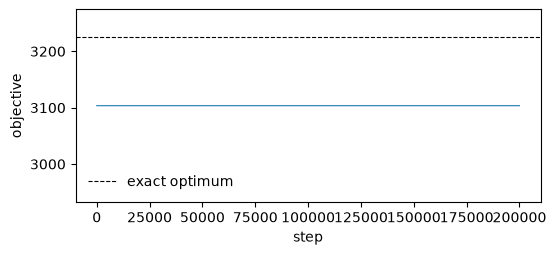

In [8]:
plt.figure(figsize=(6, 2.5))
plt.plot(np.arange(len(sampled.trace)) * sampled.trace_every, sampled.trace, lw=0.8)
plt.axhline(out["adaptive"].value, color="k", ls="--", lw=0.8, label="exact optimum")
plt.xlabel("step")
plt.ylabel("objective")
plt.legend(frameon=False);

## 3. Classic datasets

Iris and wine (standardised) and digits (PCA to 10 dimensions), Ward linkage, the same
Gaussian score. ARI compares the clusters with the true classes. The objective is not the
class labels, so a better objective does not have to mean a higher ARI: on these datasets
the change in ARI is small and goes both ways.

In [9]:
rows = points.classic()

   iris: n= 150  B=0.94  single-level  4 clusters ARI=0.59  adaptive  5 clusters ARI=0.57
   wine: n= 178  B=0.94  single-level  3 clusters ARI=0.79  adaptive  3 clusters ARI=0.79
 digits: n=1797  B=0.97  single-level 29 clusters ARI=0.47  adaptive 26 clusters ARI=0.58


Mean image of every digits cluster found by the adaptive cut, with its most common digit and
its size. Several digits split into sub-styles (two kinds of 1, 2, 4 and 7).

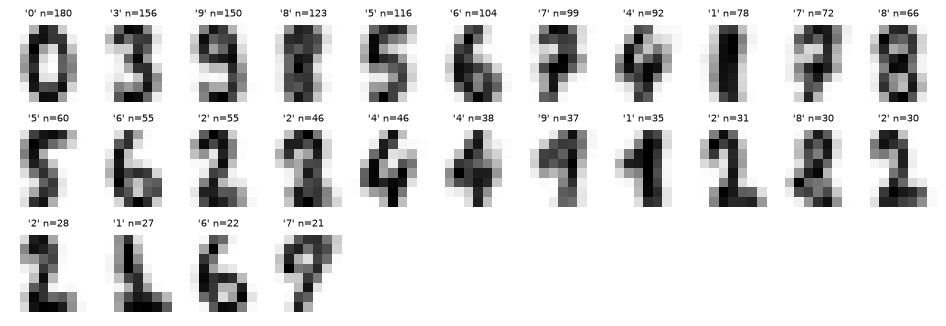

In [10]:
from sklearn.datasets import load_digits

digits = load_digits()
best = next(r for r in rows if r[0] == "digits")[4]
digits_figure(digits.images, digits.target, best);

## 4. Your own objective

`node_scores(Z, func)` evaluates `func(leaf_ids)` on every node, which is the easiest way to
plug in any per-cluster score. Here the Gaussian score is written as a plain function of one
cluster. It gives the same scores as the bottom-up `points.gaussian_scores`, which is faster on
large trees. To minimise a cost, negate it.

In [11]:
from scipy.cluster.hierarchy import linkage

X, y = points.blobs(seed=1)
Z = linkage(X, "ward")
floor = 0.01 * X.var(axis=0)


def gaussian_bic(idx):  # score of the cluster made of the points X[idx]
    x = X[idx]
    m, d = x.shape
    v = np.maximum(x.var(axis=0), floor)
    loglik = -0.5 * m * np.sum(np.log(2 * np.pi * v) + x.var(axis=0) / v)
    return loglik + m * np.log(m) - 0.5 * (2 * d + 1) * np.log(len(X))


scores = ac.node_scores(Z, gaussian_bic)
print("same as the bottom-up scores:", np.allclose(scores, points.gaussian_scores(X, Z)))
cut = ac.optimal_cut(Z, scores)
print(cut, "ARI", round(points.ari(y, cut.labels), 2))

same as the bottom-up scores: True
Cut(n_clusters=5, value=3228.69) ARI 0.98
